# Adani Group Stock Market Analysis

## Project Overview

This project analyzes historical stock-market data for companies represented in the Adani dataset.

The objective is to investigate stock-price performance, daily returns, volatility, trading activity, correlations, and market behavior around January 2023.

## Business Questions

1. How have stock prices changed over time?
2. Which companies experienced the largest cumulative price changes?
3. Which companies had the highest historical volatility?
4. How does trading volume differ across companies?
5. How correlated are daily stock returns?
6. What changed around January 24, 2023?
7. What limitations should be considered when interpreting the results?

> This project is for analytical and educational purposes and is not investment advice.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [6]:
from pathlib import Path

print(Path.cwd())

C:\Users\raphi\Downloads\adani_stock_analysis\notebooks


In [7]:
# Load Dataset

from pathlib import Path
import pandas as pd

# Project root
ROOT = Path(r"C:\Users\raphi\Downloads\adani_stock_analysis")

# Load raw dataset
df = pd.read_csv(
    ROOT / "data" / "raw" / "adani.csv"
)

# Display first 5 rows
df.head()

,timestamp,symbol,company,open,high,low,close,volume,dividends,stock_splits
0,1789669800,ACC.NS,ACC Limited,1236.599976,1279.900024,1236.599976,NaN,386560,0.0,0.0
1,1789669800,ADANIENSOL.NS,Adani Energy Solutions Limited,1380.900024,1436.500000,1380.900024,1436.099976,2145921,0.0,0.0
2,1789669800,ADANIENT.NS,Adani Enterprises Limited,2933.000000,3020.000000,2924.600098,NaN,1628125,0.0,0.0
3,1789669800,ADANIGREEN.NS,Adani Green Energy Limited,1274.199951,1337.900024,1274.199951,1334.500000,2597171,0.0,0.0
4,1789669800,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,1748.000000,1824.000000,1744.000000,1824.000000,4148803,0.0,0.0


Initial Exploration

In [8]:
df.shape

(40325, 10)

In [10]:
df.head()

,timestamp,symbol,company,open,high,low,close,volume,dividends,stock_splits
0,1789669800,ACC.NS,ACC Limited,1236.599976,1279.900024,1236.599976,NaN,386560,0.0,0.0
1,1789669800,ADANIENSOL.NS,Adani Energy Solutions Limited,1380.900024,1436.500000,1380.900024,1436.099976,2145921,0.0,0.0
2,1789669800,ADANIENT.NS,Adani Enterprises Limited,2933.000000,3020.000000,2924.600098,NaN,1628125,0.0,0.0
3,1789669800,ADANIGREEN.NS,Adani Green Energy Limited,1274.199951,1337.900024,1274.199951,1334.500000,2597171,0.0,0.0
4,1789669800,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,1748.000000,1824.000000,1744.000000,1824.000000,4148803,0.0,0.0


In [11]:
df.tail()

,timestamp,symbol,company,open,high,low,close,volume,dividends,stock_splits
40320,1025548200,ADANIENT.NS,Adani Enterprises Limited,1.386372,1.390971,1.356484,1.373344,1016147,0.0,0.0
40321,1025548200,AMBUJACEM.NS,Ambuja Cements Limited,27.990000,28.270000,27.730000,27.969999,1007265,0.0,0.0
40322,1025461800,ACC.NS,ACC Limited,160.000000,163.000000,159.000000,161.750000,659631,0.0,0.0
40323,1025461800,ADANIENT.NS,Adani Enterprises Limited,1.364148,1.401700,1.334259,1.362615,1080397,0.0,0.0
40324,1025461800,AMBUJACEM.NS,Ambuja Cements Limited,27.520000,28.129999,27.400000,27.990000,630442,0.0,0.0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40325 entries, 0 to 40324
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     40325 non-null  int64  
 1   symbol        40325 non-null  str    
 2   company       40325 non-null  str    
 3   open          40325 non-null  float64
 4   high          40325 non-null  float64
 5   low           40325 non-null  float64
 6   close         40322 non-null  float64
 7   volume        40325 non-null  int64  
 8   dividends     40325 non-null  float64
 9   stock_splits  40325 non-null  float64
dtypes: float64(6), int64(2), str(2)
memory usage: 4.4 MB


In [14]:
df.describe()

,timestamp,open,high,low,close,volume,dividends,stock_splits
count,4.032500e+04,40325.000000,40325.000000,40325.000000,40322.000000,4.032500e+04,40325.000000,40325.000000
mean,1.480727e+09,549.485030,558.347037,539.594718,548.596360,7.247622e+06,0.014865,0.000422
std,2.097943e+08,722.671983,733.462840,709.876780,721.349229,2.770678e+07,0.473858,0.044260
min,1.025462e+09,0.858340,0.928846,0.858340,0.919650,0.000000e+00,0.000000,0.000000
25%,1.313001e+09,73.000000,74.468689,71.250000,72.750000,4.412000e+05,0.000000,0.000000
50%,1.515955e+09,207.600006,211.000000,203.850006,207.125000,1.489697e+06,0.000000,0.000000
75%,1.661366e+09,817.000000,830.400024,802.000000,815.637512,4.371592e+06,0.000000,0.000000
max,1.789670e+09,4175.000000,4236.750000,4066.399902,4165.299805,1.210999e+09,58.000000,5.000000


In [16]:
df.columns

Index(['timestamp', 'symbol', 'company', 'open', 'high', 'low', 'close',
       'volume', 'dividends', 'stock_splits'],
      dtype='str')

In [17]:
df.dtypes

timestamp         int64
symbol              str
company             str
open            float64
high            float64
low             float64
close           float64
volume            int64
dividends       float64
stock_splits    float64
dtype: object

Missing Values

In [18]:
df.isnull().sum()

timestamp       0
symbol          0
company         0
open            0
high            0
low             0
close           3
volume          0
dividends       0
stock_splits    0
dtype: int64

In [19]:
df[df["close"].isna()]

,timestamp,symbol,company,open,high,low,close,volume,dividends,stock_splits
0,1789669800,ACC.NS,ACC Limited,1236.599976,1279.900024,1236.599976,NaN,386560,0.0,0.0
2,1789669800,ADANIENT.NS,Adani Enterprises Limited,2933.000000,3020.000000,2924.600098,NaN,1628125,0.0,0.0
6,1789669800,AMBUJACEM.NS,Ambuja Cements Limited,384.549988,396.000000,383.899994,NaN,2583375,0.0,0.0


In [20]:
df[df.isnull().any(axis=1)]

,timestamp,symbol,company,open,high,low,close,volume,dividends,stock_splits
0,1789669800,ACC.NS,ACC Limited,1236.599976,1279.900024,1236.599976,NaN,386560,0.0,0.0
2,1789669800,ADANIENT.NS,Adani Enterprises Limited,2933.000000,3020.000000,2924.600098,NaN,1628125,0.0,0.0
6,1789669800,AMBUJACEM.NS,Ambuja Cements Limited,384.549988,396.000000,383.899994,NaN,2583375,0.0,0.0


Duplicate records

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.duplicated(
    subset=["symbol", "timestamp"]
).sum()

np.int64(0)

In [23]:
df[df.duplicated(
    subset=["symbol", "timestamp"],
    keep=False
)]

,timestamp,symbol,company,open,high,low,close,volume,dividends,stock_splits


Convert Timestamp

In [24]:
df["date"] = pd.to_datetime(
    df["timestamp"],
    unit="s",
    utc=True
).dt.tz_convert(None)

In [25]:
df["date"].min()

Timestamp('2002-06-30 18:30:00')

In [27]:
df["date"].max()

Timestamp('2026-09-17 18:30:00')

Sort the data

In [28]:
df = df.sort_values(
    ["symbol", "date"]
).reset_index(drop=True)

Remove duplicate observations

In [29]:
df = df.drop_duplicates(
    subset=["symbol", "date"]
).reset_index(drop=True)

Examine Companies

In [30]:
df["symbol"].nunique()

11

In [32]:
df["company"].nunique()

11

In [34]:
df["symbol"].value_counts()

symbol
ADANIENT.NS      6018
AMBUJACEM.NS     6017
ACC.NS           6016
NDTV.NS          5525
ADANIPORTS.NS    4642
ADANIPOWER.NS    4219
ADANIENSOL.NS    2753
ADANIGREEN.NS    2042
ATGL.NS          1948
AWL.NS           1144
SANGHIIND.NS        1
Name: count, dtype: int64

In [36]:
df.groupby(
    ["symbol", "company"]
).size().sort_values(
    ascending=False
)

symbol         company                                      
ADANIENT.NS    Adani Enterprises Limited                        6018
AMBUJACEM.NS   Ambuja Cements Limited                           6017
ACC.NS         ACC Limited                                      6016
NDTV.NS        New Delhi Television Limited                     5525
ADANIPORTS.NS  Adani Ports and Special Economic Zone Limited    4642
ADANIPOWER.NS  Adani Power Limited                              4219
ADANIENSOL.NS  Adani Energy Solutions Limited                   2753
ADANIGREEN.NS  Adani Green Energy Limited                       2042
ATGL.NS        Adani Total Gas Limited                          1948
AWL.NS         AWL Agri Business Limited                        1144
SANGHIIND.NS   Sanghi Industries Limited                           1
dtype: int64

Feature Engineering

In [37]:
#Daily return

df["daily_return"] = (
    df.groupby("symbol")["close"]
      .pct_change(fill_method=None)
)

In [38]:
#Intraday return

df["intraday_return"] = (
    (df["close"] - df["open"]) / df["open"]
)

In [39]:
#Daily trading range

df["daily_range_pct"] = (
    (df["high"] - df["low"]) / df["open"]
)

In [40]:
#Volume Change

df["volume_change_pct"] = (
    df.groupby("symbol")["volume"]
    .pct_change(fill_method=None)
)

In [41]:
#Year

df["yaer"] = df["date"].dt.year

In [42]:
#Month

df["month"] = df["date"].dt.month

30 - day rolling volatility

In [43]:
df["rolling_volatility_30d"] = (
    df.groupby("symbol")["daily_return"]
    .transform(
        lambda x:
        x.rolling(
            window=30,
            min_periods=20
        ).std() * np.sqrt(252)
    )
)

Cumulative Return

In [44]:
df["cumulative_return"] = (
    df.groupby("symbol")["close"]
    .transform(
        lambda x:
        x / x.dropna().iloc[0] - 1
    )
)

Create Company Summary

In [45]:
company_summary = (
    df.groupby(["symbol", "company"])
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        trading_days=("date", "count"),
        average_close=("close", "mean"),
        latest_close=("close", "last"),
        average_volume=("volume", "mean"),
        annualized_volatility=(
            "daily_return",
            lambda x: x.std() * np.sqrt(252)
        ),
        total_return=(
            "close",
            lambda x:
            x.dropna().iloc[-1] /
            x.dropna().iloc[0] - 1
        )
    )
    .reset_index()
)

In [46]:
company_summary

,symbol,company,start_date,end_date,trading_days,average_close,latest_close,average_volume,annualized_volatility,total_return
0,ACC.NS,ACC Limited,2002-06-30 18:30:00,2026-09-17 18:30:00,6016,1255.181305,1232.500000,7.058044e+05,0.311898,6.619784
1,ADANIENSOL.NS,Adani Energy Solutions Limited,2015-07-30 18:30:00,2026-09-17 18:30:00,2753,779.220795,1436.099976,1.460079e+06,0.514306,51.032607
2,ADANIENT.NS,Adani Enterprises Limited,2002-06-30 18:30:00,2026-09-17 18:30:00,6018,605.723691,2923.199951,6.330169e+06,0.542237,2144.286801
3,ADANIGREEN.NS,Adani Green Energy Limited,2018-06-17 18:30:00,2026-09-17 18:30:00,2042,1019.226837,1334.500000,2.095834e+06,0.541988,41.365079
4,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,2007-11-26 18:30:00,2026-09-17 18:30:00,4642,488.889922,1824.000000,4.068931e+06,0.412281,8.509906
5,ADANIPOWER.NS,Adani Power Limited,2009-08-19 18:30:00,2026-09-17 18:30:00,4219,37.615530,206.600006,4.530015e+07,0.495173,9.319680
6,AMBUJACEM.NS,Ambuja Cements Limited,2002-06-30 18:30:00,2026-09-17 18:30:00,6017,223.199393,383.250000,3.659867e+06,1.388544,12.692390
7,ATGL.NS,Adani Total Gas Limited,2018-11-04 18:30:00,2026-09-17 18:30:00,1948,910.637577,660.700012,1.855094e+06,0.544014,7.739418
8,AWL.NS,AWL Agri Business Limited,2022-02-07 18:30:00,2026-09-17 18:30:00,1144,367.076058,186.979996,3.808519e+06,0.431213,-0.302964
9,NDTV.NS,New Delhi Television Limited,2004-05-18 18:30:00,2026-09-17 18:30:00,5525,132.975568,71.720001,2.928346e+05,0.537831,-0.278834


In [47]:
#sorting

company_summary.sort_values(
    "total_return",
    ascending=False
)

,symbol,company,start_date,end_date,trading_days,average_close,latest_close,average_volume,annualized_volatility,total_return
2,ADANIENT.NS,Adani Enterprises Limited,2002-06-30 18:30:00,2026-09-17 18:30:00,6018,605.723691,2923.199951,6.330169e+06,0.542237,2144.286801
1,ADANIENSOL.NS,Adani Energy Solutions Limited,2015-07-30 18:30:00,2026-09-17 18:30:00,2753,779.220795,1436.099976,1.460079e+06,0.514306,51.032607
3,ADANIGREEN.NS,Adani Green Energy Limited,2018-06-17 18:30:00,2026-09-17 18:30:00,2042,1019.226837,1334.500000,2.095834e+06,0.541988,41.365079
6,AMBUJACEM.NS,Ambuja Cements Limited,2002-06-30 18:30:00,2026-09-17 18:30:00,6017,223.199393,383.250000,3.659867e+06,1.388544,12.692390
5,ADANIPOWER.NS,Adani Power Limited,2009-08-19 18:30:00,2026-09-17 18:30:00,4219,37.615530,206.600006,4.530015e+07,0.495173,9.319680
4,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,2007-11-26 18:30:00,2026-09-17 18:30:00,4642,488.889922,1824.000000,4.068931e+06,0.412281,8.509906
7,ATGL.NS,Adani Total Gas Limited,2018-11-04 18:30:00,2026-09-17 18:30:00,1948,910.637577,660.700012,1.855094e+06,0.544014,7.739418
0,ACC.NS,ACC Limited,2002-06-30 18:30:00,2026-09-17 18:30:00,6016,1255.181305,1232.500000,7.058044e+05,0.311898,6.619784
10,SANGHIIND.NS,Sanghi Industries Limited,2026-04-01 18:30:00,2026-04-01 18:30:00,1,49.889999,49.889999,6.748660e+05,NaN,0.000000
9,NDTV.NS,New Delhi Television Limited,2004-05-18 18:30:00,2026-09-17 18:30:00,5525,132.975568,71.720001,2.928346e+05,0.537831,-0.278834


Output

In [48]:
company_summary.to_csv(
    ROOT / "outputs" / "company_summary.csv",
    index=False
)

Normalized price performance

In [49]:
plot_df = df.dropna(
    subset=["close"]
).copy()

plot_df["price_index"] = (
    plot_df.groupby("symbol")["close"]
    .transform(
        lambda x:
        x / x.iloc[0] * 100
    )
)

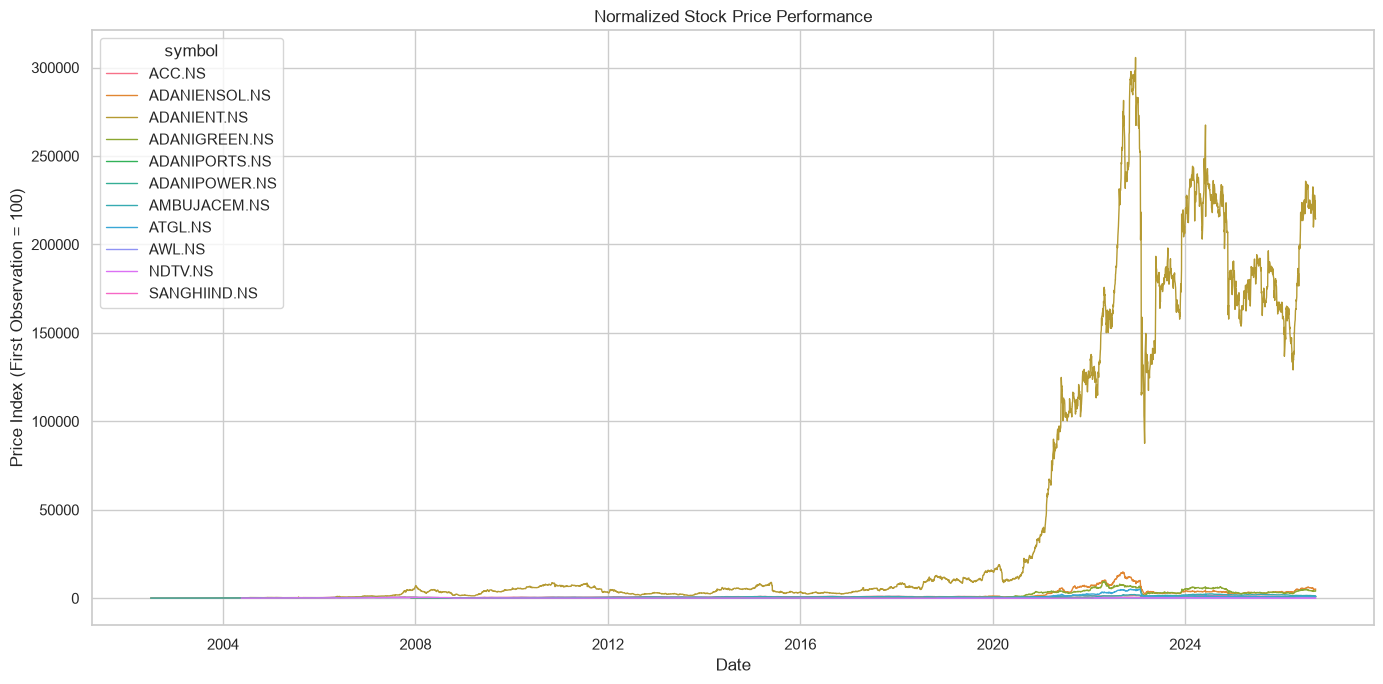

In [50]:
#make the chart

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=plot_df,
    x="date",
    y="price_index",
    hue="symbol",
    linewidth=1
)

plt.title(
    "Normalized Stock Price Performance"
)

plt.xlabel("Date")
plt.ylabel(
    "Price Index "
    "(First Observation = 100)"
)

plt.tight_layout()
plt.show()

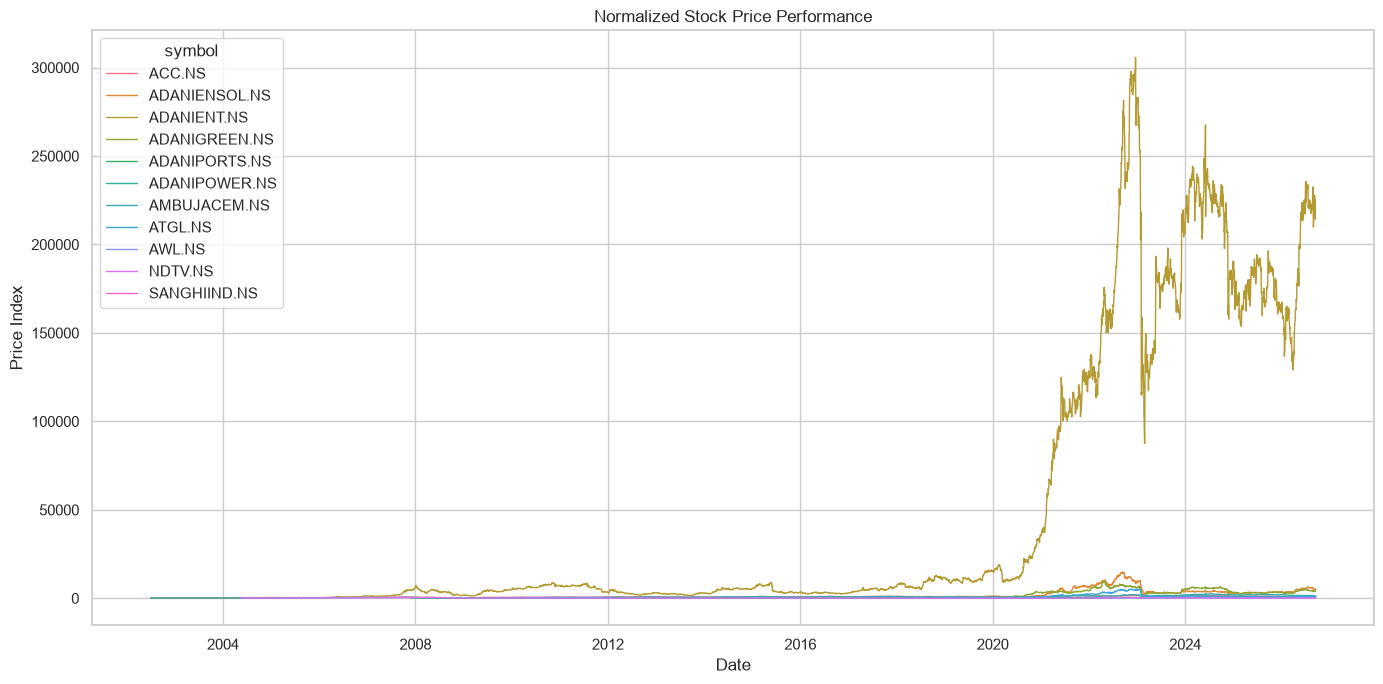

In [51]:
#Save the chart

figure_path = (
    ROOT /
    "outputs" /
    "figures" /
    "normalized_price_performance.png"
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=plot_df,
    x="date",
    y="price_index",
    hue="symbol",
    linewidth=1
)

plt.title(
    "Normalized Stock Price Performance"
)

plt.xlabel("Date")
plt.ylabel("Price Index")

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Volatility 

In [52]:
volatility_df = (
    df.groupby("symbol")["daily_return"]
    .std()
    .mul(np.sqrt(252))
    .reset_index(
        name="annualized_volatility"
    )
)

In [53]:
#sort
volatility_df = volatility_df.sort_values(
    "annualized_volatility",
    ascending=False
)

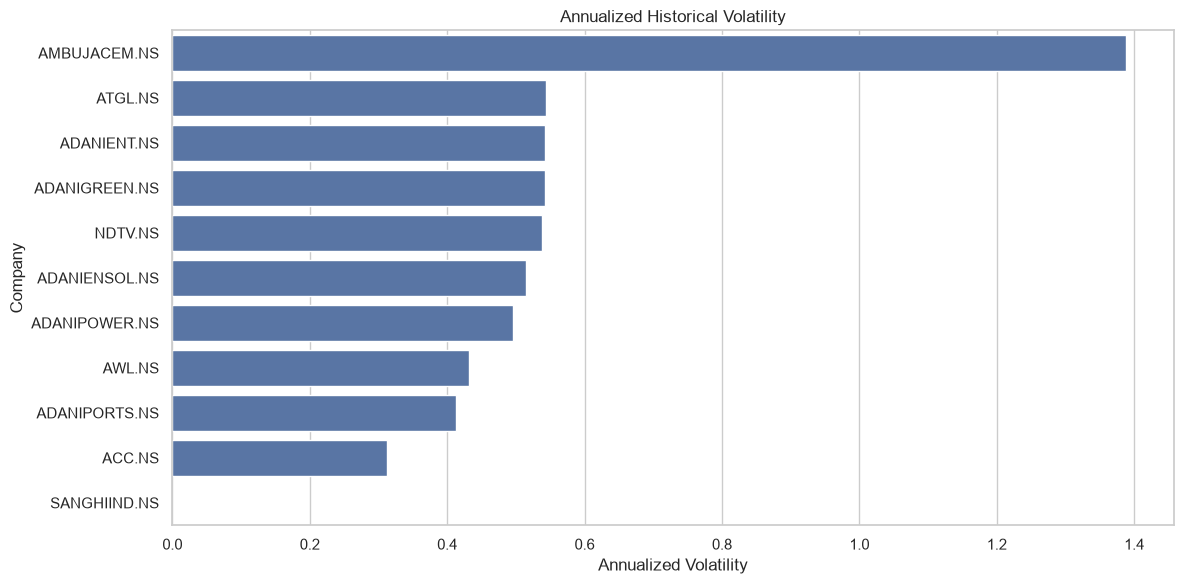

In [54]:
#chart

plt.figure(figsize=(12, 6))

sns.barplot(
    data=volatility_df,
    x="annualized_volatility",
    y="symbol"
)

plt.title(
    "Annualized Historical Volatility"
)

plt.xlabel("Annualized Volatility")
plt.ylabel("Company")

plt.tight_layout()

plt.show()

In [55]:
#save
plt.savefig(
    ROOT /
    "outputs" /
    "figures" /
    "annualized_volatility.png",
    dpi=200,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
Trading Volume

In [56]:
volume_summary = (
    df.groupby(
        ["symbol", "company"]
    )["volume"]
    .agg(
        average_volume="mean",
        median_volume="median",
        maximum_volume="max"
    )
    .reset_index()
)

In [57]:
volume_summary.sort_values(
    "average_volume",
    ascending=False
)

,symbol,company,average_volume,median_volume,maximum_volume
5,ADANIPOWER.NS,Adani Power Limited,4.530015e+07,23192425.0,1210999365
2,ADANIENT.NS,Adani Enterprises Limited,6.330169e+06,3872487.0,177391228
4,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,4.068931e+06,2661284.0,115517458
8,AWL.NS,AWL Agri Business Limited,3.808519e+06,1725310.0,135533461
6,AMBUJACEM.NS,Ambuja Cements Limited,3.659867e+06,2470415.0,91035714
3,ADANIGREEN.NS,Adani Green Energy Limited,2.095834e+06,1125283.5,55121312
7,ATGL.NS,Adani Total Gas Limited,1.855094e+06,763123.5,57324845
1,ADANIENSOL.NS,Adani Energy Solutions Limited,1.460079e+06,762098.0,46087335
0,ACC.NS,ACC Limited,7.058044e+05,419661.0,13441088
10,SANGHIIND.NS,Sanghi Industries Limited,6.748660e+05,674866.0,674866


Correlation

In [58]:
returns = df.pivot(
    index="date",
    columns="symbol",
    values="daily_return"
)

In [59]:
correlation = returns.corr()

In [60]:
correlation

symbol,ACC.NS,ADANIENSOL.NS,ADANIENT.NS,ADANIGREEN.NS,ADANIPORTS.NS,ADANIPOWER.NS,AMBUJACEM.NS,ATGL.NS,AWL.NS,NDTV.NS,SANGHIIND.NS
symbol,,,,,,,,,,,
ACC.NS,1.000000,0.345215,0.331402,0.334996,0.401900,0.332317,0.167881,0.343140,0.359775,0.258744,NaN
ADANIENSOL.NS,0.345215,1.000000,0.464975,0.545266,0.423495,0.439754,0.346814,0.627505,0.432641,0.207281,NaN
ADANIENT.NS,0.331402,0.464975,1.000000,0.466143,0.530591,0.519301,0.081730,0.482917,0.485505,0.243038,NaN
ADANIGREEN.NS,0.334996,0.545266,0.466143,1.000000,0.424738,0.455592,0.360297,0.522801,0.439587,0.198894,NaN
ADANIPORTS.NS,0.401900,0.423495,0.530591,0.424738,1.000000,0.445129,0.380525,0.424229,0.443691,0.236141,NaN
ADANIPOWER.NS,0.332317,0.439754,0.519301,0.455592,0.445129,1.000000,0.323936,0.459369,0.553605,0.245265,NaN
AMBUJACEM.NS,0.167881,0.346814,0.081730,0.360297,0.380525,0.323936,1.000000,0.335624,0.359823,0.081494,NaN
ATGL.NS,0.343140,0.627505,0.482917,0.522801,0.424229,0.459369,0.335624,1.000000,0.447316,0.242034,NaN
AWL.NS,0.359775,0.432641,0.485505,0.439587,0.443691,0.553605,0.359823,0.447316,1.000000,0.325969,NaN


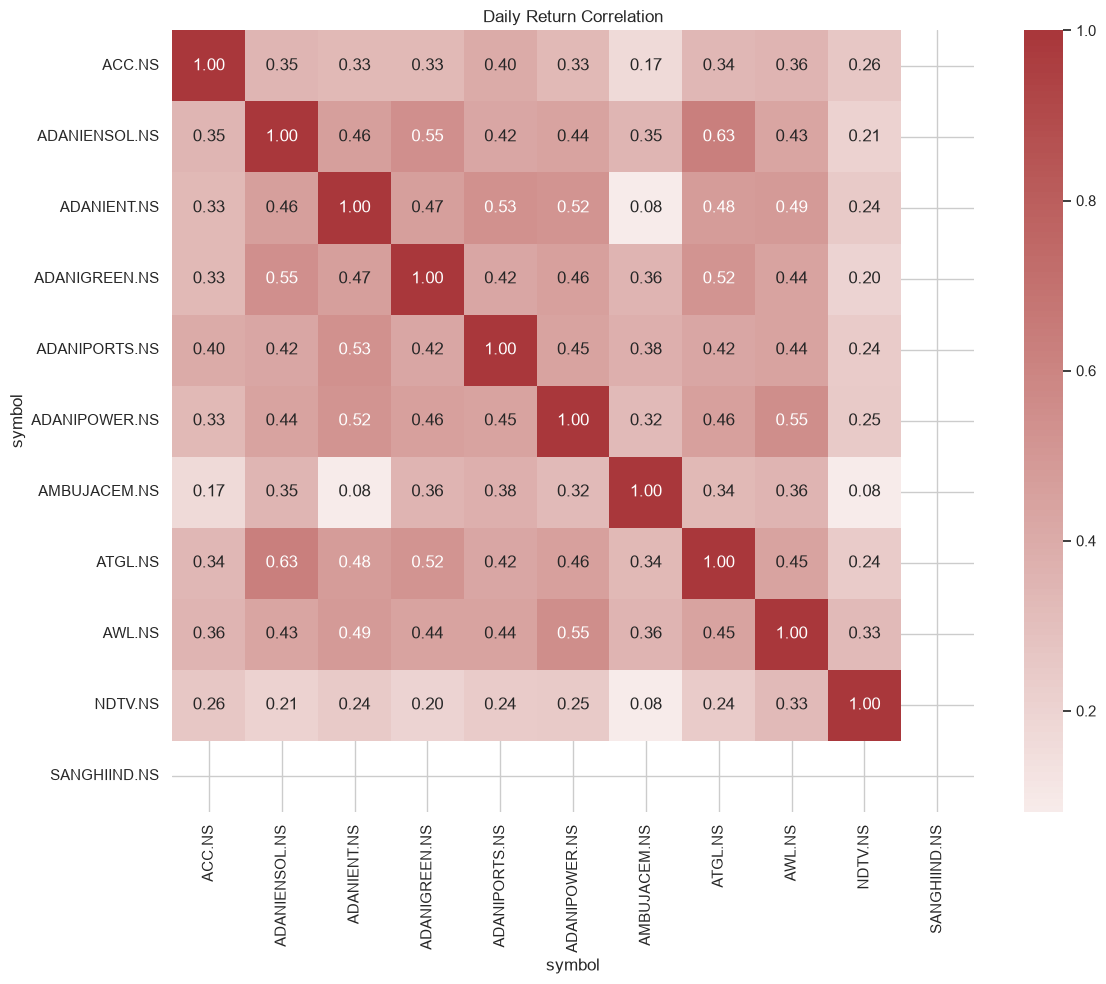

In [61]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0
)

plt.title(
    "Daily Return Correlation"
)

plt.tight_layout()

plt.show()

In [62]:
#save
plt.savefig(
    ROOT /
    "outputs" /
    "figures" /
    "return_correlation.png",
    dpi=200,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

January 2023 analysis

In [63]:
event_date = pd.Timestamp(
    "2023-01-24"
)

In [64]:
#create window

event_df = df[
    (
        df["date"] >=
        event_date - pd.Timedelta(days=45)
    )
    &
    (
        df["date"] <=
        event_date + pd.Timedelta(days=45)
    )
    ].copy()

In [65]:
#create before and after

event_df["period"] = np.where(
    event_df["date"] < event_date,
    "Before",
    "After"
)

In [66]:
event_summary = (
    event_df
    .groupby(["symbol", "period"])
    .agg(
        average_return=("daily_return", "mean"),
        volatility=("daily_return", "std"),
        average_volume=("volume", "mean")
    )
    .reset_index()
)

In [67]:
#View

event_summary

,symbol,period,average_return,volatility,average_volume
0,ACC.NS,After,-0.006894,0.035906,1.605674e+06
1,ACC.NS,Before,-0.003465,0.015126,2.980082e+05
2,ADANIENSOL.NS,After,-0.033271,0.064194,1.350578e+06
3,ADANIENSOL.NS,Before,0.001784,0.030163,5.551922e+05
4,ADANIENT.NS,After,-0.012688,0.111223,1.590673e+07
5,ADANIENT.NS,Before,-0.004420,0.021944,1.800381e+06
6,ADANIGREEN.NS,After,-0.030479,0.066215,3.500370e+06
7,ADANIGREEN.NS,Before,-0.001681,0.031011,1.176724e+06
8,ADANIPORTS.NS,After,-0.000774,0.062826,2.877625e+07
9,ADANIPORTS.NS,Before,-0.004724,0.018820,4.208794e+06


In [68]:
#save

event_summary.to_csv(
    ROOT /
    "outputs" /
    "january_2023_event_summary.csv",
    index=False
)

In [69]:
df.to_csv(
    ROOT / "data" / "adani_cleaned.csv",
    index=False
)